In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# CyberSentryFusion — Model Testing & Validation

## 1. Objective

The objective of this notebook is to evaluate the reliability and predictive performance of the trained XGBoost intrusion detection model using the UNSW-NB15 testing dataset.

We will assess the model's ability to distinguish between normal network traffic and malicious traffic, investigate classification errors, and examine the effect of different decision thresholds.

## 2. Testing Approach

The notebook will cover:

* Loading the trained model and saved decision threshold.
* Preparing the testing dataset.
* Generating predictions on unseen test data.
* Evaluating performance using accuracy, precision, recall, and F1-score.
* Analyzing the confusion matrix.
* Investigating false positives and false negatives.
* Examining ROC-AUC and decision threshold behavior.
* Summarizing the model's strengths and limitations.

## 3. Analogy: A Cybersecurity Examination

Imagine the trained model as a cybersecurity detective.

During training, the detective learned patterns from previously examined network traffic. During testing, the detective receives separate cases that were not used to train it.

We evaluate the detective by comparing its predictions with the known labels.

A reliable evaluation helps us understand how well the model performs on the test dataset. It does not, by itself, guarantee performance on real-world network traffic.


## 4. Load the Model, Threshold, and Dataset

We begin by loading the previously trained XGBoost pipeline, its saved decision threshold, and the UNSW-NB15 training and testing datasets.

### Key components

* **Trained model:** The saved pipeline containing preprocessing and the XGBoost classifier.
* **Decision threshold:** The probability cutoff used to classify traffic as an attack.
* **Training dataset:** Used to verify the data structure and feature preparation.
* **Testing dataset:** Used to evaluate predictions on data separate from the training dataset.

We will reuse the existing trained model rather than retraining it in this notebook.


In [1]:

# STEP 1: LOAD MODEL, THRESHOLD, AND DATA


import os
import joblib
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Dataset and model paths
DATA_DIR = "/kaggle/input/datasets/uzairsidd/cyber-sentry-dataset"
MODEL_DIR = "/kaggle/input/datasets/uzairsidd/cybersentry-models"

# Load the trained model pipeline
model = joblib.load(
    os.path.join(MODEL_DIR, "xgboost_model.joblib")
)

# Load the saved decision threshold
threshold = float(
    joblib.load(
        os.path.join(MODEL_DIR, "threshold.joblib")
    )
)

# Load datasets
train_df = pd.read_csv(
    os.path.join(DATA_DIR, "UNSW_NB15_training-set.csv")
)

test_df = pd.read_csv(
    os.path.join(DATA_DIR, "UNSW_NB15_testing-set.csv")
)

# Display basic information
print("Model type:", type(model).__name__)
print("Decision threshold:", threshold)

print("\nTraining dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)

print("\nPipeline steps:")
print(list(model.named_steps.keys()))

Model type: Pipeline
Decision threshold: 0.5

Training dataset shape: (175341, 45)
Testing dataset shape: (82332, 45)

Pipeline steps:
['preprocessor', 'classifier']


## 5. Verify the Loaded Data

Before evaluating the model, we verify that the datasets contain the expected columns and that the saved model pipeline loaded successfully.

The UNSW-NB15 datasets include input features and target-related columns.

We must separate the model's input features from the target labels to avoid accidentally providing information that should not be available as an input during prediction.

This step helps prevent data leakage and ensures that evaluation reflects the intended prediction task.


In [2]:
print("Training columns:")
print(train_df.columns.tolist())

print("\nTesting columns:")
print(test_df.columns.tolist())

print("\nMissing values in testing data:", test_df.isnull().sum().sum())

print("\nTraining label distribution:")
print(train_df["label"].value_counts().sort_index())

print("\nTesting label distribution:")
print(test_df["label"].value_counts().sort_index())

print("\nFirst five testing rows:")
display(test_df.head())

Training columns:
['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label']

Testing columns:
['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.000011,udp,-,INT,2,0,496,0,90909.0902,...,1,2,0,0,0,1,2,0,Normal,0
1,2,0.000008,udp,-,INT,2,0,1762,0,125000.0003,...,1,2,0,0,0,1,2,0,Normal,0
2,3,0.000005,udp,-,INT,2,0,1068,0,200000.0051,...,1,3,0,0,0,1,3,0,Normal,0
3,4,0.000006,udp,-,INT,2,0,900,0,166666.6608,...,1,3,0,0,0,2,3,0,Normal,0
4,5,0.000010,udp,-,INT,2,0,2126,0,100000.0025,...,1,3,0,0,0,2,3,0,Normal,0


## 6. Separate Input Features and Target Labels

Before testing the model, we need to separate the input features from the actual labels.

* **`X_test`**: Contains the 42 network traffic features used to make predictions.
* **`y_test`**: Contains the actual labels: `0` for normal traffic and `1` for attack traffic.

We remove `id`, `attack_cat`, and `label` from the input features to prevent the model from using identifiers, attack-category information, or the target label during prediction.

The trained pipeline will handle preprocessing consistently with the training process.


In [3]:
# Separate the actual labels
y_test = test_df["label"].astype(int)

# Keep only the input features
X_test = test_df.drop(columns=["id", "attack_cat", "label"])

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)
print("Number of features:", X_test.shape[1])
print("Target classes:", sorted(y_test.unique()))
print("Missing values:", X_test.isnull().sum().sum())

X_test shape: (82332, 42)
y_test shape: (82332,)
Number of features: 42
Target classes: [np.int64(0), np.int64(1)]
Missing values: 0


## 7. Generate Model Predictions

Now we will pass the test dataset through our trained XGBoost pipeline to predict whether each network connection is normal or malicious.

The model produces an attack probability for every record. We then apply our saved decision threshold of `0.5` to classify each record.

* **Probability ≥ 0.5:** Predict attack (`1`).
* **Probability < 0.5:** Predict normal (`0`).

We will use the existing saved threshold rather than adjust it based on test results, keeping the test dataset reserved for unbiased evaluation.


In [4]:
# Predict the probability of attack (class 1)
y_prob = model.predict_proba(X_test)[:, 1]

# Convert probabilities into binary predictions
y_pred = (y_prob >= threshold).astype(int)

print("Decision threshold:", threshold)
print("Total test samples:", len(y_test))

print("\nPredicted normal samples:", (y_pred == 0).sum())
print("Predicted attack samples:", (y_pred == 1).sum())

print("\nFirst 10 attack probabilities:")
print(np.round(y_prob[:10], 4))

print("\nFirst 10 predicted labels:")
print(y_pred[:10])

print("\nFirst 10 actual labels:")
print(y_test.iloc[:10].to_numpy())

Decision threshold: 0.5
Total test samples: 82332

Predicted normal samples: 27565
Predicted attack samples: 54767

First 10 attack probabilities:
[9.081e-01 8.411e-01 7.063e-01 7.145e-01 7.220e-01 8.867e-01 8.777e-01
 6.999e-01 7.000e-04 7.000e-04]

First 10 predicted labels:
[1 1 1 1 1 1 1 1 0 0]

First 10 actual labels:
[0 0 0 0 0 0 0 0 0 0]


## 8. Evaluate Model Performance

Now that predictions have been generated, we will compare them against the actual labels to evaluate the performance of CyberSentryFusion.

We will calculate the following metrics:

* **Accuracy:** Percentage of all predictions that are correct.
* **Precision:** Percentage of predicted attacks that are actually attacks.
* **Recall:** Percentage of actual attacks correctly detected by the model.
* **F1-score:** Balance between precision and recall.
* **ROC-AUC:** Measures how well the model distinguishes attacks from normal traffic across different thresholds.

We will also display the classification report to examine performance separately for normal traffic and attack traffic.

These metrics will help us understand not only how often the model is correct, but also how effectively it detects attacks and how frequently it raises false alarms.


In [5]:
# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)

print("========== MODEL EVALUATION ==========")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

print("\n========== CLASSIFICATION REPORT ==========")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Normal", "Attack"],
        zero_division=0
    )
)


========== MODEL EVALUATION ==========
Accuracy : 0.8728
Precision: 0.8183
Recall   : 0.9886
F1-score : 0.8954
ROC-AUC  : 0.9844

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

      Normal       0.98      0.73      0.84     37000
      Attack       0.82      0.99      0.90     45332

    accuracy                           0.87     82332
   macro avg       0.90      0.86      0.87     82332
weighted avg       0.89      0.87      0.87     82332



## 9. Confusion Matrix Analysis

A confusion matrix helps us understand the types of predictions our model makes.

It compares the model's predictions with the actual labels and divides the results into four categories:

* **True Negative (TN):** Normal traffic correctly classified as normal.
* **False Positive (FP):** Normal traffic incorrectly classified as an attack.
* **False Negative (FN):** An actual attack incorrectly classified as normal.
* **True Positive (TP):** An actual attack correctly classified as an attack.

In cybersecurity, false negatives are particularly important because they represent attacks that the model fails to detect. False positives also matter because excessive false alarms can overwhelm security analysts.


Confusion Matrix:
[[27048  9952]
 [  517 44815]]


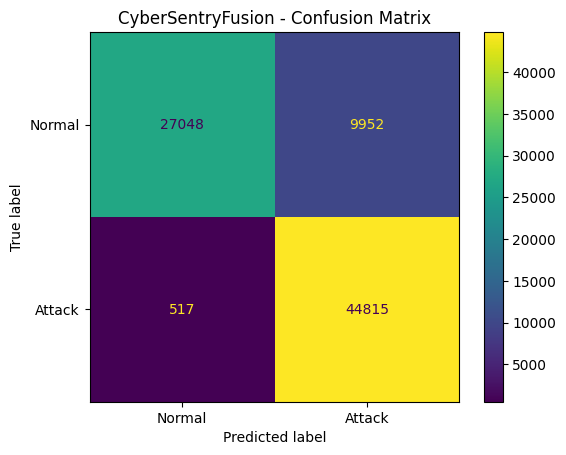

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)

# Plot the confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Attack"]
)

display.plot(values_format="d")
plt.title("CyberSentryFusion - Confusion Matrix")
plt.show()

## 10. Analyze False Positives and False Negatives

Accuracy alone does not explain how a cybersecurity model behaves. We must also measure how often it raises false alarms or misses real attacks.

We will calculate:

* **Specificity:** Proportion of normal connections correctly identified.
* **False Positive Rate (FPR):** Proportion of normal connections incorrectly flagged as attacks.
* **False Negative Rate (FNR):** Proportion of actual attacks missed by the model.

These metrics help us evaluate whether CyberSentryFusion balances attack detection with a manageable number of false alarms.


In [7]:
# Extract confusion matrix values
tn, fp, fn, tp = cm.ravel()

# Calculate additional metrics
specificity = tn / (tn + fp)
fpr = fp / (fp + tn)
fnr = fn / (fn + tp)

print("========== ERROR ANALYSIS ==========")
print(f"True Negatives (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"True Positives (TP): {tp}")

print(f"\nSpecificity:          {specificity:.4f} ({specificity * 100:.2f}%)")
print(f"False Positive Rate:  {fpr:.4f} ({fpr * 100:.2f}%)")
print(f"False Negative Rate:  {fnr:.4f} ({fnr * 100:.2f}%)")

========== ERROR ANALYSIS ==========
True Negatives (TN): 27048
False Positives (FP): 9952
False Negatives (FN): 517
True Positives (TP): 44815

Specificity:          0.7310 (73.10%)
False Positive Rate:  0.2690 (26.90%)
False Negative Rate:  0.0114 (1.14%)


In [ ]:
## 11 . Analyze Prediction Confidence

A binary prediction tells us whether the model classified a connection as normal or an attack. However, the predicted probability tells us how strongly the model leans toward the attack class.

We will examine the distribution of predicted attack probabilities to understand how confidently CyberSentryFusion classifies network traffic.

* Probabilities close to `0` indicate a low estimated likelihood of an attack.
* Probabilities close to `1` indicate a high estimated likelihood of an attack.
* The decision threshold of `0.5` separates normal predictions from attack predictions.

**Note:** These probabilities represent the model's estimates and are not necessarily perfectly calibrated real-world probabilities.


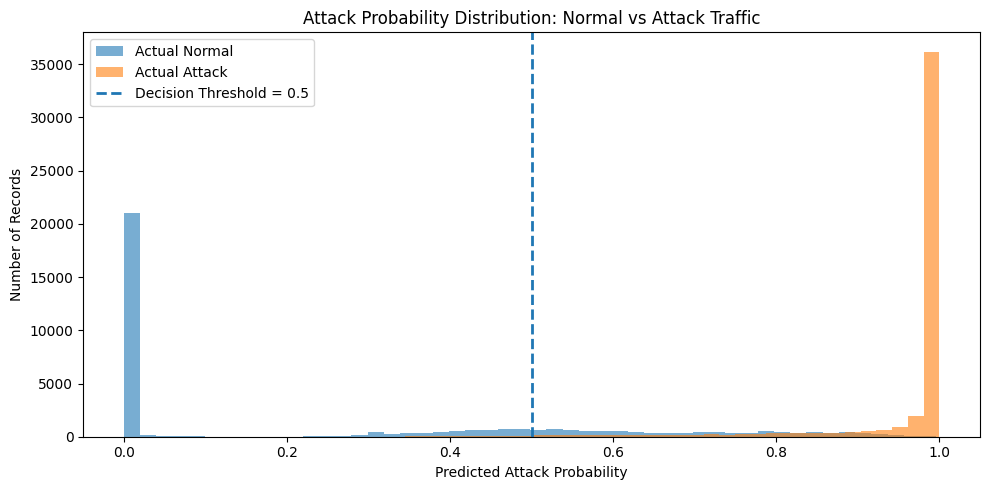

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(y_prob[y_test.to_numpy() == 0], bins=50, alpha=0.6, label="Actual Normal")
plt.hist(y_prob[y_test.to_numpy() == 1], bins=50, alpha=0.6, label="Actual Attack")

plt.axvline(
    threshold,
    linestyle="--",
    linewidth=2,
    label=f"Decision Threshold = {threshold}"
)

plt.xlabel("Predicted Attack Probability")
plt.ylabel("Number of Records")
plt.title("Attack Probability Distribution: Normal vs Attack Traffic")
plt.legend()
plt.tight_layout()
plt.show()

## 11. Analyze Prediction Errors

Even when a model performs well overall, examining individual mistakes can reveal useful patterns.

In this section, we will identify:

* **False positives:** Normal connections incorrectly predicted as attacks.
* **False negatives:** Actual attacks incorrectly predicted as normal.

We will inspect a small sample of each error type, including their actual labels, predicted labels, predicted attack probabilities, and selected network traffic features.

This analysis can help us understand the kinds of records the model struggles to classify. It does not, by itself, establish why an error occurred.


In [10]:
import numpy as np
from IPython.display import display as show_table

# Convert actual labels into a NumPy array
y_true = y_test.to_numpy()

# Find indices of false positives and false negatives
false_positive_indices = np.where(
    (y_true == 0) & (y_pred == 1)
)[0]

false_negative_indices = np.where(
    (y_true == 1) & (y_pred == 0)
)[0]


def inspect_errors(indices, error_type, n=5):
    sample_indices = indices[:n]

    error_df = X_test.iloc[sample_indices].copy()
    error_df["actual_label"] = y_true[sample_indices]
    error_df["predicted_label"] = y_pred[sample_indices]
    error_df["attack_probability"] = y_prob[sample_indices]
    error_df["error_type"] = error_type

    return error_df


# Inspect false positives
false_positives = inspect_errors(
    false_positive_indices, "False Positive"
)

print("False positives inspected:", len(false_positives))
show_table(false_positives)

# Inspect false negatives
false_negatives = inspect_errors(
    false_negative_indices, "False Negative"
)

print("\nFalse negatives inspected:", len(false_negatives))
show_table(false_negatives)

False positives inspected: 5


,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,...,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,actual_label,predicted_label,attack_probability,error_type
0,0.000011,udp,-,INT,2,0,496,0,90909.0902,254,...,0,0,0,1,2,0,0,1,0.908124,False Positive
1,0.000008,udp,-,INT,2,0,1762,0,125000.0003,254,...,0,0,0,1,2,0,0,1,0.841086,False Positive
2,0.000005,udp,-,INT,2,0,1068,0,200000.0051,254,...,0,0,0,1,3,0,0,1,0.706260,False Positive
3,0.000006,udp,-,INT,2,0,900,0,166666.6608,254,...,0,0,0,2,3,0,0,1,0.714463,False Positive
4,0.000010,udp,-,INT,2,0,2126,0,100000.0025,254,...,0,0,0,2,3,0,0,1,0.722028,False Positive



False negatives inspected: 5


,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,...,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,actual_label,predicted_label,attack_probability,error_type
254,0.409782,tcp,http,FIN,10,8,852,1336,41.485474,62,...,0,0,1,2,2,0,1,0,0.470161,False Negative
277,0.523646,tcp,-,FIN,10,6,674,268,28.645306,254,...,0,0,0,1,7,0,1,0,0.454912,False Negative
282,0.566928,tcp,-,FIN,10,6,490,268,26.458385,254,...,0,0,0,1,6,0,1,0,0.432446,False Negative
295,0.772218,tcp,http,FIN,10,10,808,1238,24.604451,62,...,0,0,1,1,3,0,1,0,0.477502,False Negative
309,0.596682,tcp,-,FIN,12,6,3678,268,28.490887,254,...,0,0,0,2,5,0,1,0,0.487308,False Negative


## 12. Analyze Confidence in Misclassified Records

A model can make mistakes with either high or low confidence.

In this section, we will compare the predicted attack probabilities of false positives and false negatives.

This analysis helps us distinguish between:

* **High-confidence mistakes:** Incorrect predictions made with strong model confidence.
* **Low-confidence mistakes:** Incorrect predictions made near the decision threshold.

Understanding these cases can help identify opportunities for further investigation and model improvement.


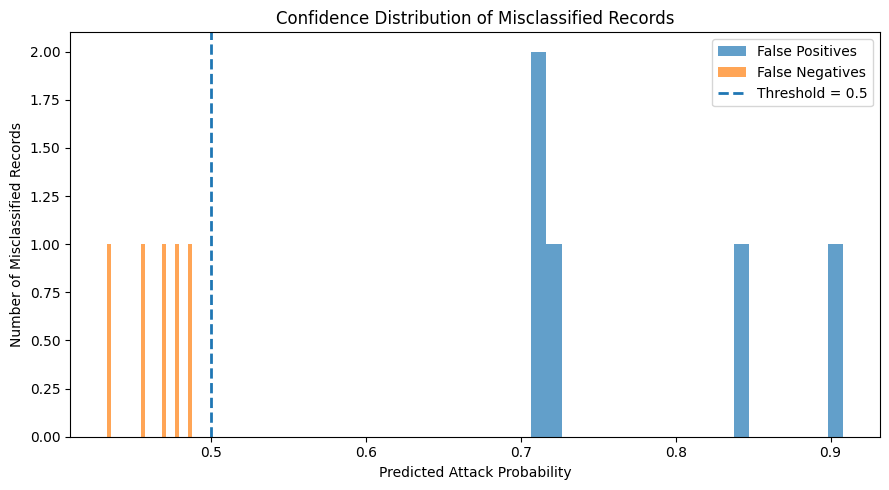

False positive probability range: 0.7063 to 0.9081
False negative probability range: 0.4324 to 0.4873


In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.hist(
    false_positives["attack_probability"],
    bins=20,
    alpha=0.7,
    label="False Positives"
)

plt.hist(
    false_negatives["attack_probability"],
    bins=20,
    alpha=0.7,
    label="False Negatives"
)

plt.axvline(
    threshold,
    linestyle="--",
    linewidth=2,
    label=f"Threshold = {threshold}"
)

plt.xlabel("Predicted Attack Probability")
plt.ylabel("Number of Misclassified Records")
plt.title("Confidence Distribution of Misclassified Records")
plt.legend()
plt.tight_layout()
plt.show()

print(
    "False positive probability range:",
    round(false_positives["attack_probability"].min(), 4),
    "to",
    round(false_positives["attack_probability"].max(), 4)
)

print(
    "False negative probability range:",
    round(false_negatives["attack_probability"].min(), 4),
    "to",
    round(false_negatives["attack_probability"].max(), 4)
)

## 13. Test Prediction Consistency

Before finalizing the evaluation, we should verify that the trained pipeline produces consistent predictions when the same records are evaluated repeatedly.

This test will:

* Select a small sample of test records.
* Generate attack probabilities twice using the same trained model.
* Compare the results to verify that predictions remain consistent.

This is a basic reproducibility check. It does not establish performance on new datasets or guarantee robustness against unseen attacks.


In [12]:
# Select five test records
X_sample_test = X_test.iloc[:5]

# Generate predictions twice
probabilities_first = model.predict_proba(X_sample_test)[:, 1]
probabilities_second = model.predict_proba(X_sample_test)[:, 1]

# Compare the results
consistent = np.allclose(
    probabilities_first,
    probabilities_second
)

print("First run: ", np.round(probabilities_first, 6))
print("Second run:", np.round(probabilities_second, 6))
print("\nPredictions consistent:", consistent)

if consistent:
    print("PASS: Repeated predictions are consistent.")
else:
    print("FAIL: Repeated predictions differ.")

First run:  [0.908124 0.841086 0.70626  0.714463 0.722028]
Second run: [0.908124 0.841086 0.70626  0.714463 0.722028]

Predictions consistent: True
PASS: Repeated predictions are consistent.


## 

## 14. Summarize Model Testing Results

In this section, we consolidate the key evaluation metrics and error counts into one summary.

The summary includes accuracy, precision, recall, F1-score, ROC-AUC, false positives, and false negatives.

This provides a concise overview of CyberSentryFusion's performance on the test dataset and highlights the trade-off between detecting attacks and avoiding false alarms.

These results apply to the current test dataset and decision threshold of `0.5`.


In [14]:
# Create a consolidated evaluation summary
results_summary = pd.DataFrame({
    "Metric": [
        "Test Samples",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC",
        "True Negatives",
        "False Positives",
        "False Negatives",
        "True Positives",
        "Specificity",
        "False Positive Rate",
        "False Negative Rate",
        "Decision Threshold"
    ],
    "Value": [
        len(y_test),
        round(accuracy, 4),
        round(precision, 4),
        round(recall, 4),
        round(f1, 4),
        round(roc_auc, 4),
        int(tn),
        int(fp),
        int(fn),
        int(tp),
        round(specificity, 4),
        round(fpr, 4),
        round(fnr, 4),
        threshold
    ]
})

from IPython.display import display as show_table

show_table(results_summary)

,Metric,Value
0,Test Samples,82332.0000
1,Accuracy,0.8728
2,Precision,0.8183
3,Recall,0.9886
4,F1-Score,0.8954
5,ROC-AUC,0.9844
6,True Negatives,27048.0000
7,False Positives,9952.0000
8,False Negatives,517.0000
9,True Positives,44815.0000


## 15. Testing Conclusions and Limitations

### Key Findings

* The model achieved **87.28% accuracy** and **98.86% attack recall** on the test dataset.
* The ROC-AUC score of **98.44%** indicates strong separation between normal and attack traffic.
* The model correctly detected 44,815 attacks and missed 517.
* The model incorrectly flagged 9,952 normal records as attacks, resulting in a false positive rate of 26.90%.

### Limitations

* The evaluation uses the UNSW-NB15 dataset and does not establish performance on live network traffic.
* The false positive rate may be too high for some operational cybersecurity environments.
* The saved threshold of 0.5 has not been optimized for a particular operational requirement in this notebook.
* Additional testing is needed to assess robustness on different datasets and previously unseen traffic.

### Conclusion

CyberSentryFusion demonstrates promising attack-detection performance on the current test dataset. Further evaluation and false-positive reduction should be considered before using it in a real-world security environment.
